# 4. Final candidates, test predictions and inferences
Load the frozen logistic regression and 8-neuron NN, their existing validation thresholds and their saved test predictions.

Test evaluation already happened in the original project. These are the same final results, not a new independent test. Models remain trained on 3,000 employees; validation/test are not used for refitting. Existing test scores load by default.

LR is the default candidate for simplicity and lower fitting cost; the small NN is a challenger. The 40%/60% labels are validation recall targets; realized test recall can differ. The business operating policy has not yet been agreed.

In [1]:
# Import the tools used in this notebook.
import os
for setting in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ[setting] = '1'
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
# Locate the repository even before its local data has been downloaded.
from pathlib import Path
PROJECT = Path.cwd()
if not (PROJECT / '01_EDA.ipynb').exists():
    PROJECT = PROJECT / 'attrition'
assert (PROJECT / '01_EDA.ipynb').exists(), 'Open from the repository root or its parent.'

# Create output folders before exporting the frozen comparison.
for folder in ['artifacts/final', 'results/tables']:
    (PROJECT / folder).mkdir(parents=True, exist_ok=True)


In [2]:
# Load raw splits without depending on another notebook's kernel.
manifest = json.loads((PROJECT / 'artifacts/manifest.json').read_text(encoding='utf-8'))
def load_split(name):
    import hashlib
    for prefix in ['X', 'y']:
        relative_path = f'data/splits/{prefix}_{name}.csv'
        actual_hash = hashlib.sha256((PROJECT / relative_path).read_bytes()).hexdigest()
        assert actual_hash == manifest['files'][relative_path], 'Split file changed: ' + relative_path
    predictors = pd.read_csv(PROJECT / f'data/splits/X_{name}.csv',
                             index_col='row_id', float_precision='round_trip')
    target = pd.read_csv(PROJECT / f'data/splits/y_{name}.csv', index_col='row_id')['attrition']
    assert predictors.index.equals(target.index) and predictors.index.is_unique
    assert target.isin([0, 1]).all() and len(target) == manifest['split_sizes'][name]
    assert {col: str(dtype) for col, dtype in predictors.dtypes.items()} == manifest['raw_dtypes']
    assert predictors.columns.tolist() == manifest['raw_predictors']
    return predictors, target
X_train, y_train = load_split('train')
X_val, y_val = load_split('validation')
print('Loaded training/validation rows:', len(X_train), len(X_val))

Loaded training/validation rows: 3000 1000


In [3]:
# Load the frozen models, validation scores and original evaluation plan.
import joblib
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
    precision_score, recall_score, f1_score, accuracy_score, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve)
X_test, y_test = load_split('test')
fitted_candidates = joblib.load(PROJECT / 'artifacts/models/focused_tuned_models.joblib')
validation_cache = np.load(PROJECT / 'artifacts/scores/focused_tuning_scores.npz', allow_pickle=False)
cached_validation = pd.DataFrame(validation_cache['scores'], columns=validation_cache['columns'],
                                 index=validation_cache['row_index'])
np.testing.assert_array_equal(validation_cache['row_index'], y_val.index)
np.testing.assert_array_equal(validation_cache['target'], y_val.to_numpy())
test_plan = json.loads((PROJECT / 'artifacts/test_evaluation_plan.json').read_text(encoding='utf-8'))
frozen_thresholds = test_plan['thresholds']
test_models = {'Logistic regression': fitted_candidates['LR: CV best'],
               'Small NN (8 neurons)': fitted_candidates['NN: Economical']}
candidate_keys = {'Logistic regression': 'LR: CV best', 'Small NN (8 neurons)': 'NN: Economical'}
for name, model in test_models.items():
    np.testing.assert_allclose(model.predict_proba(X_val)[:, 1],
                               cached_validation[candidate_keys[name]], rtol=1e-10, atol=1e-10)
display(pd.DataFrame(frozen_thresholds).T.round(6))

,Default 0.50,Validation recall target 40%,Validation recall target 60%
Logistic regression,0.5,0.240400,0.169858
Small NN (8 neurons),0.5,0.247253,0.187823


In [4]:
# Reuse saved test probabilities without fitting or selecting thresholds.
test_cache = np.load(PROJECT / 'artifacts/scores/final_test_scores.npz', allow_pickle=False)
np.testing.assert_array_equal(test_cache['row_index'], y_test.index)
np.testing.assert_array_equal(test_cache['target'], y_test.to_numpy())
test_probabilities = pd.DataFrame(test_cache['scores'], columns=test_cache['columns'],
                                  index=y_test.index)
# Optional reproducibility check only; neither model is fitted or changed.
VERIFY_FROZEN_PREDICTIONS = False
if VERIFY_FROZEN_PREDICTIONS:
    for name, model in test_models.items():
        np.testing.assert_allclose(model.predict_proba(X_test)[:, 1],
                                   test_probabilities[name], rtol=1e-10, atol=1e-10)

In [5]:
# Compare ranking and decisions using the frozen policies.
test_ranking = pd.DataFrame({
    name: {
        'Validation AP': average_precision_score(y_val, cached_validation[candidate_keys[name]]),
        'Test AP': average_precision_score(y_test, probability),
        'Test ROC-AUC': roc_auc_score(y_test, probability)
    }
    for name, probability in test_probabilities.items()
}).T
print('Test employees:', len(y_test), '| Leavers:', int(y_test.sum()),
      '| Stayed:', int((y_test == 0).sum()))
display(test_ranking.round(4))

# Evaluate the predefined default, 40%-target, and 60%-target thresholds.
test_decision_rows = []
for name, probability in test_probabilities.items():
    for operating_point, threshold in frozen_thresholds[name].items():
        prediction = (probability >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, prediction, labels=[0, 1]).ravel()
        test_decision_rows.append({
            'Model': name, 'Operating point': operating_point, 'Threshold': threshold,
            'Precision': precision_score(y_test, prediction, zero_division=0),
            'Recall': recall_score(y_test, prediction, zero_division=0),
            'F1': f1_score(y_test, prediction, zero_division=0),
            'Accuracy': accuracy_score(y_test, prediction),
            'Detected leavers': int(tp), 'False alerts': int(fp),
            'Missed leavers': int(fn), 'Correct stays': int(tn), 'Alerts': int(tp + fp)
        })
test_decisions = pd.DataFrame(test_decision_rows)
display(test_decisions.round(4))

Test employees: 1000 | Leavers: 163 | Stayed: 837


,Validation AP,Test AP,Test ROC-AUC
Logistic regression,0.2973,0.2695,0.7078
Small NN (8 neurons),0.3000,0.2746,0.7100


,Model,Operating point,Threshold,Precision,Recall,F1,Accuracy,Detected leavers,False alerts,Missed leavers,Correct stays,Alerts
0,Logistic regression,Default 0.50,0.5000,0.2727,0.0184,0.0345,0.832,3,8,160,829,11
1,Logistic regression,Validation recall target 40%,0.2404,0.3095,0.3988,0.3485,0.757,65,145,98,692,210
2,Logistic regression,Validation recall target 60%,0.1699,0.2688,0.6564,0.3815,0.653,107,291,56,546,398
3,Small NN (8 neurons),Default 0.50,0.5000,0.0000,0.0000,0.0000,0.837,0,0,163,837,0
4,Small NN (8 neurons),Validation recall target 40%,0.2473,0.3196,0.4294,0.3665,0.758,70,149,93,688,219
5,Small NN (8 neurons),Validation recall target 60%,0.1878,0.2677,0.6258,0.3750,0.660,102,279,61,558,381


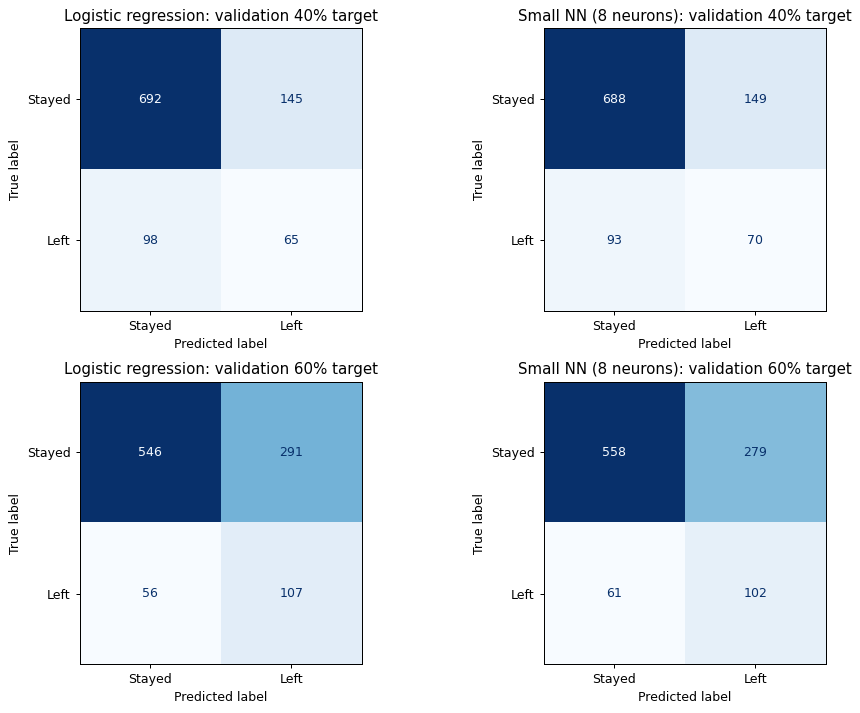

In [6]:
# Show confusion matrices at the two validation-defined operating points.
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for row, target in enumerate([0.40, 0.60]):
    operating_point = f'Validation recall target {target:.0%}'
    for col, (name, probability) in enumerate(test_probabilities.items()):
        prediction = (probability >= frozen_thresholds[name][operating_point]).astype(int)
        ConfusionMatrixDisplay.from_predictions(
            y_test, prediction, labels=[0, 1], display_labels=['Stayed', 'Left'],
            cmap='Blues', colorbar=False, values_format='d', ax=axes[row, col]
        )
        axes[row, col].set_title(f'{name}: validation {target:.0%} target')
plt.tight_layout()
plt.show()


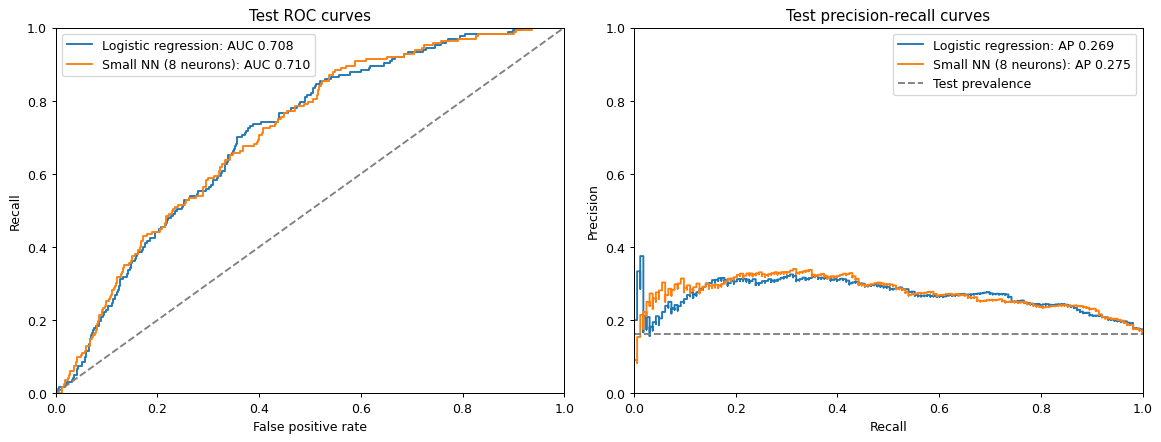

In [7]:
# Plot test ranking performance without selecting new test-based thresholds.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, probability in test_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probability)
    precision, recall, _ = precision_recall_curve(y_test, probability)
    axes[0].plot(fpr, tpr, label=f'{name}: AUC {roc_auc_score(y_test, probability):.3f}')
    axes[1].step(recall, precision, where='post',
                 label=f'{name}: AP {average_precision_score(y_test, probability):.3f}')
axes[0].plot([0, 1], [0, 1], '--', color='grey')
axes[1].axhline(y_test.mean(), linestyle='--', color='grey', label='Test prevalence')
axes[0].set(title='Test ROC curves', xlabel='False positive rate', ylabel='Recall')
axes[1].set(title='Test precision-recall curves', xlabel='Recall', ylabel='Precision')
for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend()
plt.tight_layout()
plt.show()


In [8]:
# Quantify uncertainty in the AP difference using paired, stratified resampling.
# This resamples test rows only; neither model is refitted or changed.
rng = np.random.default_rng(42)
positive = np.flatnonzero(y_test.to_numpy() == 1)
negative = np.flatnonzero(y_test.to_numpy() == 0)
ap_differences = []
for repeat in range(500):
    sample = np.concatenate([
        rng.choice(positive, len(positive), replace=True),
        rng.choice(negative, len(negative), replace=True)
    ])
    target = y_test.to_numpy()[sample]
    nn_ap = average_precision_score(target, test_probabilities['Small NN (8 neurons)'].to_numpy()[sample])
    lr_ap = average_precision_score(target, test_probabilities['Logistic regression'].to_numpy()[sample])
    ap_differences.append(nn_ap - lr_ap)

ap_difference_interval = np.quantile(ap_differences, [0.025, 0.975])
print('Test AP difference (NN minus LR):',
      round(test_ranking.loc['Small NN (8 neurons)', 'Test AP']
            - test_ranking.loc['Logistic regression', 'Test AP'], 4))
print('Approximate paired-bootstrap 95% interval:', ap_difference_interval.round(4))


Test AP difference (NN minus LR): 0.0051
Approximate paired-bootstrap 95% interval: [-0.0082  0.019 ]


**Reading the test results:** use the validation-frozen operating points. Do not lower or raise their thresholds to make test recall equal a target. Both models predict exactly the same held-out employees, so alert counts are directly comparable, but realized recall may differ.

Logistic regression: test AP 0.2695, ROC-AUC 0.7078.
Small NN (8 neurons): test AP 0.2746, ROC-AUC 0.7100.

**Uncertainty:** the approximate 95% paired-bootstrap interval for NN minus LR AP is [-0.0082, 0.0190]. It includes zero, so this test sample does not establish a clear AP advantage. Stratified resampling fixes class prevalence and does not retrain models.

**Limits and cost:** the test set has now been used to compare two preselected models; keep these results as the final held-out comparison rather than continuing to tune against it. Prior EDA viewed full-dataset distributions, and validation was reused during development. Refer to measured fit/prediction times and parameter counts; actual electrical energy was not measured. A final operating decision depends on the value of missed leavers versus false alerts. No model or threshold is changed automatically.

**Held-out findings:** LR test AP was 0.2695 and NN AP 0.2746; ROC-AUC was 0.7078 versus 0.7100. The AP difference was +0.0051 for NN, with an approximate paired-bootstrap 95% interval of [-0.0082, 0.0190]. This does not demonstrate a clear AP advantage for either model.

At the frozen validation-40% thresholds, LR detected 65 leavers with 145 false alerts; NN detected 70 with 149. At the validation-60% thresholds, LR detected 107 with 291 false alerts; NN detected 102 with 279. Realized test recall differs, so these are frozen-policy comparisons rather than exactly matched test-recall comparisons. Neither model dominates both policies.

**Recommendation:** keep LR as the default final candidate for its simpler structure, stronger mean training-CV AP, and lower fitting cost. Retain the 8-neuron NN as a challenger if its extra detections at the lower-alert operating point are worth the extra alerts and complexity. Its small ranking gain does not clearly justify replacement on current evidence. Prediction-time differences were small and actual energy use remains unmeasured.

**Current status:** both shortlisted models have now been evaluated on the reserved test set with settings and thresholds frozen in advance, as requested. Do not tune against these results or select a new test-based threshold. The remaining decision is the intended recall/alert budget and the corresponding previously evaluated policy; deployment packaging and any genuinely independent future evaluation are separate steps.

In [9]:
# Export raw-input pipelines, policy options and final report tables.
joblib.dump(test_models['Logistic regression'], PROJECT / 'artifacts/final/logistic_regression.joblib')
joblib.dump(test_models['Small NN (8 neurons)'], PROJECT / 'artifacts/final/neural_network_challenger.joblib')
final_policy = {
    'default_candidate': 'Logistic regression', 'challenger': 'Small NN (8 neurons)',
    'selected_operating_point': None,
    'reason_pending': 'Agree on recall/alert budget; do not optimize thresholds using test data.',
    'threshold_options_from_validation': frozen_thresholds,
    'input_columns': manifest['raw_predictors'], 'positive_class': 1,
    'trained_rows': 3000, 'test_already_evaluated': True,
    'preprocessing_included': True, 'versions': manifest['versions']
}
(PROJECT / 'artifacts/final/model_policy.json').write_text(json.dumps(final_policy, indent=2), encoding='utf-8')
test_ranking.to_csv(PROJECT / 'results/tables/final_test_ranking.csv')
test_decisions.to_csv(PROJECT / 'results/tables/final_test_decisions.csv', index=False)
test_probabilities.to_csv(PROJECT / 'results/tables/final_test_probabilities.csv', index_label='row_id')
print('Saved both raw-input pipelines, frozen policy options and final tables.')

Saved both raw-input pipelines, frozen policy options and final tables.
